# ROMS Hawaiʻi forecast, best series: virtual Icechunk smoke test (local)

A smoke test for the virtual Icechunk store planned in
[issue #10](https://github.com/ocean-icechunks/pacioos/issues/10): the PacIOOS ROMS 7-day
forecast for the main Hawaiian Islands (`roms_hiig`), served as PacIOOS's THREDDS serves it, as
one **"best" time series** across the daily runs. The data are read from the unchanged NetCDF
copies on Source Cooperative:

`https://data.source.coop/ocean-icechunks/pacioos/roms_hiig/netcdf/<year>/hiig_forec_<YYYYMMDD>.nc`

The store holds only Zarr metadata and byte-range references. No array data is copied, and every
read goes back to those files. The planned destination is
`ocean-icechunks/pacioos/roms_hiig/icechunk/`. **This notebook does not write there.** It writes
only to a temporary local directory, which it deletes at the end.

## What this notebook does

1. Checks that the copies serve byte ranges.
2. Inspects one file: NetCDF-3 records, offsets and the metadata problems.
3. Checks the layout across files. The forecast files come in **four header layouts** (two
   header lengths × an `int16` or `float32` mask), so offsets differ between files; what must
   agree is everything else.
4. Takes the metadata repairs from PacIOOS's ERDDAP record, saved in `erddap_metadata.json`.
5. Builds the best series from three overlapping runs, with **one depth plane per chunk**
   (references cut inside each NetCDF-3 record slab: the HYCOM trick).
6. Writes it to a local Icechunk repo, reopens it read-only as a reader would, and checks the
   best rule, the structure and the values against netCDF-C.
7. Builds a series with a **gap no run covers**, and checks the decision for gaps: a regular
   axis, NaN data and NaT `forecast_reference_time`.
8. Times a map, a profile and a point series.
9. Lists what is still unknown before the production build.

## Running it

No credentials. It reads the public copies anonymously over HTTPS, and the ERDDAP metadata
from the saved copy (ERDDAP is asked only whether anything changed, if it answers). About 2
minutes. Install with `pip install -r requirements.txt` in this folder (Python 3.12 or newer).

The build code is in `forecast_store.py`, beside this notebook, shared with the production
build (`build_store.py`). This notebook calls it and shows what it does. Its source is
`make_smoke_notebook.py`.

**Decisions** (Eli Holmes, 2026-11-14, issue #10): the same as the reanalysis store, so one
depth plane per chunk, metadata from ERDDAP, one group and native `lat`/`lon`, with the title
ending ": Forecast". The THREDDS best rule. A regular 3-hourly axis, with a time that no run
covers kept as a NaN step.

In [1]:
import sys
# pacioos_virtual.py (the shared reference helpers) lives one level up, in stores/.
sys.path.insert(0, '..')

import shutil
import tempfile
import time
import urllib.request
from pathlib import Path

import fsspec
import icechunk
import kerchunk
import matplotlib.pyplot as plt
import netCDF4
import numpy as np
import pandas as pd
import virtualizarr
import xarray as xr
import zarr

import forecast_store as fs
import pacioos_virtual as pv

# Local-filesystem storage logs a warning about concurrent commits on every open;
# this notebook commits from one process, so show errors only.
icechunk.set_logs_filter('error')

for name, mod in [('icechunk', icechunk), ('virtualizarr', virtualizarr), ('xarray', xr),
                  ('zarr', zarr), ('kerchunk', kerchunk), ('netCDF4', netCDF4), ('numpy', np)]:
    print(f'{name:13s}{mod.__version__}')
print(f'{"python":13s}{sys.version.split()[0]}')

icechunk     2.3.1
virtualizarr 2.8.0
xarray       2026.9.0
zarr         3.4.2
kerchunk     0.2.10
netCDF4      1.7.5.1.post1
numpy        2.5.4
python       3.12.12


**Tested environment.** See the printed versions above: the saved outputs are from the last
end-to-end run, in a clean Python 3.12 venv holding only `requirements.txt`.

## 1. Configuration

`ZARR_CONCURRENCY` is recorded with every timing below. At Zarr's default of 10 the read
timings would measure the default setting, not the store.

In [2]:
URL_PREFIX = fs.URL_PREFIX       # https://data.source.coop/ocean-icechunks/pacioos/
SCIENCE = fs.SCIENCE             # temp, salt, u, v, zeta
FILL = fs.FILL                   # 9.99e10, what land holds in every file

RUNS = fs.list_runs()            # anonymous listing of the copies
print(f'{len(RUNS)} runs on Source Cooperative, {RUNS[0]:%Y-%m-%d} .. {RUNS[-1]:%Y-%m-%d}')
missing = pd.date_range(RUNS[0], RUNS[-1], freq='D').difference(RUNS)
longest = max((len(g) for g in np.split(missing, np.where(np.diff(missing) != pd.Timedelta('1D'))[0] + 1)),
              default=0)
print(f'{len(missing)} days without a run; longest run of missing days: {longest}')

WORK = Path(tempfile.mkdtemp(prefix='pacioos-forecast-smoke-'))
ZARR_CONCURRENCY = 128
zarr.config.set({'async.concurrency': ZARR_CONCURRENCY})
http = fsspec.filesystem('https')
print('work dir:', WORK)

654 runs on Source Cooperative, 2025-01-01 .. 2026-11-12
27 days without a run; longest run of missing days: 3
work dir: /tmp/pacioos-forecast-smoke-_li930ri


## 2. Byte-range access

A virtual store is only usable if the host answers ranged GETs with `206` and the right bytes.
A NetCDF-3 classic file starts with `CDF\x01`.

In [3]:
req = urllib.request.Request(URL_PREFIX + fs.key(RUNS[0]), headers={'Range': 'bytes=0-3'})
with urllib.request.urlopen(req) as r:
    status, body = r.status, r.read()
    print('status       ', status)
    print('content-range', r.headers.get('Content-Range'))
    print('first bytes  ', body)
assert status == 206, 'the host did not honour the range request'
assert body == b'CDF\x01', 'not NetCDF-3 classic'

status        206
content-range bytes 0-3/1901895420
first bytes   b'CDF\x01'


## 3. One file, inspected

`pv.scan_nc3` parses the header with kerchunk's NetCDF-3 reader and returns, per variable, the
shape, dtype and attributes, and the byte offset of every record slab, plus the times and the
small coordinates.

In [4]:
t0 = time.perf_counter()
s0 = pv.scan_nc3(fs.key(RUNS[0]))
print(f'scanned {s0["key"]} in {time.perf_counter() - t0:.1f}s\n')
rows = []
for name, v in s0['vars'].items():
    rows.append({'variable': name, 'dims': v['dims'], 'dtype': v['dtype'], 'slabs': len(v['offsets']),
                 'slab bytes': int(v['nbytes'][0]), 'first offset': int(v['offsets'][0]),
                 'attributes': v['attrs']})
print(pd.DataFrame(rows).to_string(index=False))
print('\ntime:', s0['time'][0], '...', s0['time'][-1], f'({len(s0["time"])} steps)')

scanned roms_hiig/netcdf/2025/hiig_forec_20250101.nc in 1.7s

variable                    dims dtype  slabs  slab bytes  first offset                                                                                  attributes
     lat                  (lat,)   >f4      1         780          1536                                         {'long_name': 'Latitude', 'units': 'degrees_north'}
     lon                  (lon,)   >f4      1        1180          2316                                         {'long_name': 'Longitude', 'units': 'degrees_east'}
   depth                (depth,)   >f4      1         144          3496                        {'long_name': 'Z-Level Depth', 'units': 'meter', 'positive': 'down'}
    mask              (lat, lon)   >i2      1      115050          3640                                     {'long_name': 'field mask', 'value': '0-land, 1-water'}
    time                 (time,)   >f4     57           4        118692      {'long_name': 'time since initialization'

In [5]:
# time is the record dimension: each step's slab of a variable sits one record (33.4 MB)
# after the previous one, and one slab is 36 (lat, lon) planes back to back, in C order.
for name in SCIENCE:
    v = s0['vars'][name]
    nz = v['shape'][1] if len(v['shape']) == 4 else 1
    assert (v['nbytes'] == nz * fs.PLANE).all() and (np.diff(v['offsets'].astype('int64')) == fs.RECSIZE).all()
    print(f'{name:5s} {len(v["offsets"])} slabs of {int(v["nbytes"][0]):>9,} bytes = {nz:2d} planes x {fs.PLANE:,};'
          f' slab spacing {fs.RECSIZE:,}')

temp  57 slabs of 8,283,600 bytes = 36 planes x 230,100; slab spacing 33,364,504
salt  57 slabs of 8,283,600 bytes = 36 planes x 230,100; slab spacing 33,364,504
u     57 slabs of 8,283,600 bytes = 36 planes x 230,100; slab spacing 33,364,504
v     57 slabs of 8,283,600 bytes = 36 planes x 230,100; slab spacing 33,364,504
zeta  57 slabs of   230,100 bytes =  1 planes x 230,100; slab spacing 33,364,504


What the scan shows, and what the store has to repair:

- Land holds **`9.99e10`**, declared as `missing_value` (no `_FillValue`). The store declares
  `_FillValue = 9.99e10` so readers mask it. ERDDAP shows `NaN` because it converts the values;
  a virtual store serves the files' bytes, so it cannot.
- `salt` has **no units**. The global attributes are just `author`, `history` and
  `title = "Zlevel Model Data"`.
- `time` is `float32` hours since 2000-01-01. That is exact for 3-hourly values.

## 4. The layout across files

The audit (`audit/report.md`) found four file sizes. The header is 4 bytes longer in some files
(a longer `history` string), and the `mask` is `int16` in some and `float32` in others, which
shifts every later offset. So **every file gives its own references**, and the production build
scans every header. What has to agree for the files to share one array is shapes, dtypes,
record size, slab sizes, coordinate and mask values, and the time steps. This samples each
layout and both sides of each change, plus the year boundary.

In [6]:
SAMPLE = pd.to_datetime(['2025-01-01', '2025-02-28', '2025-03-01', '2025-10-17', '2025-10-18',
                         '2025-12-31', '2026-01-01', '2026-02-28', '2026-03-01', '2026-08-24',
                         '2026-08-31', str(RUNS[-1].date())])
assert SAMPLE.isin(RUNS).all()


def structure(s):
    """What must be equal across files: everything except the byte offsets."""
    return {n: (s['vars'][n]['shape'], s['vars'][n]['dtype'], s['vars'][n]['nbytes'].tolist(),
                np.diff(s['vars'][n]['offsets'].astype('int64')).tolist()) for n in SCIENCE}


t0 = time.perf_counter()
layout, sample_scans = [], {}
for day in SAMPLE:
    s = s0 if day == RUNS[0] else pv.scan_nc3(fs.key(day))
    sample_scans[day] = s
    expected_t = day + pd.to_timedelta(np.arange(fs.STEPS_PER_RUN) * 3, 'h')
    layout.append({
        'file': s['key'].rsplit('/', 1)[1], 'size': http.info(URL_PREFIX + s['key'])['size'],
        'mask dtype': s['vars']['mask']['dtype'], 'temp offset': int(s['vars']['temp']['offsets'][0]),
        'same structure': structure(s) == structure(s0),
        'same coords+mask': all(np.array_equal(s['coords'][c], s0['coords'][c]) for c in ('lat', 'lon', 'depth', 'mask')),
        'times = 57 steps from 00Z': bool((s['time'] == expected_t).all()),
        'missing_value = FILL': all(np.float32(s['vars'][n]['attrs']['missing_value']) == FILL for n in SCIENCE),
    })
layout = pd.DataFrame(layout)
print(layout.to_string(index=False))
print(f'\n{len(layout)} files scanned in {time.perf_counter() - t0:.0f}s')
assert layout[['same structure', 'same coords+mask', 'times = 57 steps from 00Z', 'missing_value = FILL']].all().all()
assert layout['temp offset'].nunique() == 4, 'expected the four header layouts'

                  file       size mask dtype  temp offset  same structure  same coords+mask  times = 57 steps from 00Z  missing_value = FILL
hiig_forec_20250101.nc 1901895420        >i2     16915996            True              True                       True                  True
hiig_forec_20250228.nc 1901895420        >i2     16915996            True              True                       True                  True
hiig_forec_20250301.nc 1901895416        >i2     16915992            True              True                       True                  True
hiig_forec_20251017.nc 1901895420        >i2     16915996            True              True                       True                  True
hiig_forec_20251018.nc 1902010512        >f4     17031088            True              True                       True                  True
hiig_forec_20251231.nc 1902010512        >f4     17031088            True              True                       True                  True
hiig_forec_20

## 5. Metadata from PacIOOS's ERDDAP, saved in the repository

PacIOOS's ERDDAP serves the forecast best series as `roms_hiig` (temp, salt, u, v) and
`roms_hiig_ssh` (zeta), with corrected attributes. The store takes, from ERDDAP:

- every science variable's `long_name`, `standard_name` and `units` (`_FillValue` is the
  files' `9.99e10`, see above);
- the CF attributes of the coordinates (ERDDAP calls them `latitude`/`longitude`; the store
  keeps the files' `lat`/`lon`);
- the global attributes, except those that only drive ERDDAP's own displays and the coverage,
  which is computed from the store. The title ends ": Forecast" instead of ": 3-D Variables",
  because the store also holds `zeta`.

`mask` keeps its attributes from the file. The build reads the saved copy,
`erddap_metadata.json`, not ERDDAP, which restarts now and then. `fs.save_erddap_metadata()`
refreshes it; review the diff before committing.

In [7]:
main_attrs, ssh_attrs, fetched = fs.load_metadata()
print(f'saved ERDDAP metadata, fetched {fetched}')
diffs = fs.compare_with_live_erddap()          # None when ERDDAP does not answer
if diffs is not None:
    print('live ERDDAP:', 'no differences' if diffs.empty else '')
    if not diffs.empty:
        print(diffs.to_string(index=False))

VAR_ATTRS = fs.variable_attrs(main_attrs, ssh_attrs, s0['vars']['mask']['attrs'])

changes = []
for name in SCIENCE + ['lat', 'lon', 'depth', 'time']:
    file_attrs = s0['vars'][name]['attrs']
    for k, new in VAR_ATTRS[name].items():
        old = file_attrs.get(k, '(none)')
        if str(old) != str(new):
            changes.append({'variable': name, 'attribute': k, 'file': old, 'store': new})
print()
print(pd.DataFrame(changes).to_string(index=False))
g = fs.global_attrs(main_attrs, RUNS, RUNS)
print(f'\n{len(g)} global attributes; title: {g["title"]!r}')

saved ERDDAP metadata, fetched 2026-11-14T02:40:40Z


live ERDDAP: no differences

variable     attribute                      file                                        store
    temp standard_name                    (none)              sea_water_potential_temperature
    temp    _FillValue                    (none)                                99899998208.0
    salt standard_name                    (none)                           sea_water_salinity
    salt         units                    (none)                                         1e-3
    salt    _FillValue                    (none)                                99899998208.0
       u     long_name      u-momentum component                         u-velocity component
       u standard_name                    (none)                  eastward_sea_water_velocity
       u    _FillValue                    (none)                                99899998208.0
       v     long_name      v-momentum component                         v-velocity component
       v standard_name         

## 6. The best series from three overlapping runs

The runs of 2026-10-06, -08 and -09 (there is no 10-07 run). Each is 7 days long, so they
overlap. `pv.best_assignment` lays them on one regular 3-hourly axis, and where runs overlap,
the newest one wins, including at its own first step (lead 0). This is the rule checked against
ERDDAP `roms_hiig` in issue #10: at two overlap times the ERDDAP value matched only the
newest run's value.

`pv.manifest_variable` writes, for each step and depth, a reference to one 230,100-byte
`(lat, lon)` plane: `record_offset + k × 230,100` inside that step's record slab.

| Chunk | Bytes | One surface map | Point series, one depth, 1 year |
|---|---|---|---|
| record slab `(1, 36, 195, 295)` | 8.3 MB | 8.3 MB | 24 GB |
| **`(1, 1, 195, 295)` per depth** | **230 KB** | **230 KB** | **0.7 GB** |

Two coordinates on `time` record where each value came from: `forecast_reference_time` (the
run) and `forecast_period` (hours since the run's start), as THREDDS's best dataset has.

In [8]:
SMALL = pd.to_datetime(['2026-10-06', '2026-10-08', '2026-10-09'])
t0 = time.perf_counter()
small_scans = [pv.scan_nc3(fs.key(d)) for d in SMALL]
print(f'scanned {len(small_scans)} files in {time.perf_counter() - t0:.1f}s')

small = fs.build_dataset(small_scans, VAR_ATTRS, main_attrs)
temp = small['temp'].data
print('temp:', temp.shape, 'chunks', temp.metadata.chunks, '| codec', temp.metadata.codecs)
print('reference [time 0, depth 1]:', temp.manifest.dict()['0.1.0.0'])
print('record slab 0 starts at     ', int(small_scans[0]['vars']['temp']['offsets'][0]),
      f'(+ {fs.PLANE:,} = one plane in)')

scanned 3 files in 4.5s


temp: (81, 36, 195, 295) chunks (1, 1, 195, 295) | codec (BytesCodec(endian='big'),)
reference [time 0, depth 1]: {'path': 'https://data.source.coop/ocean-icechunks/pacioos/roms_hiig/netcdf/2026/hiig_forec_20261006.nc', 'offset': 17146096, 'length': 230100}
record slab 0 starts at      16915996 (+ 230,100 = one plane in)


## 7. Write a local repository, reopen it as a reader

The repository config names one virtual chunk container,
`https://data.source.coop/ocean-icechunks/pacioos/` (the trailing `/` is required), and
`save_config()` stores it in the repo so a reader can discover it. Manifests split on `time`
every 2,920 steps (one year), as planned for production.

The reader is a new `Repository.open` with nothing carried over from the writer: the
containers come from the saved config, each authorized for anonymous HTTP, as a reader of the
published store will do it. It is opened decoded, as a reader sees it, and raw
(`mask_and_scale=False`) for byte comparisons.

In [9]:
def write_local(ds, name):
    path = WORK / name
    repo = icechunk.Repository.create(icechunk.local_filesystem_storage(str(path)),
                                      config=fs.repository_config(),
                                      authorize_virtual_chunk_access=pv.reader_authorization())
    repo.save_config()
    session = repo.writable_session('main')
    ds.vz.to_icechunk(session.store)
    session.commit(f'{name}: {ds.attrs["forecast_runs"]}')
    return path


def open_reader(path, **kw):
    return fs.open_store(icechunk.local_filesystem_storage(str(path)), **kw)


small_path = write_local(small, 'small')
t0 = time.perf_counter()
ds = open_reader(small_path)
print(f'opened in {time.perf_counter() - t0:.2f}s')
raw = open_reader(small_path, mask_and_scale=False)
ds

opened in 0.03s


<xarray.Dataset> Size: 3GB
Dimensions:                  (lat: 195, lon: 295, time: 81, depth: 36)
Coordinates:
  * lat                      (lat) float32 780B 17.02 17.05 ... 23.95 23.98
  * lon                      (lon) float32 1kB -163.8 -163.8 ... -152.6 -152.5
  * time                     (time) datetime64[ns] 648B 2026-10-06 ... 2026-1...
    forecast_period          (time) float32 324B ...
    forecast_reference_time  (time) datetime64[ns] 648B ...
  * depth                    (depth) float32 144B 0.25 1.0 2.0 ... 5e+03 5.5e+03
Data variables:
    mask                     (lat, lon) int16 115kB ...
    temp                     (time, depth, lat, lon) float32 671MB ...
    u                        (time, depth, lat, lon) float32 671MB ...
    zeta                     (time, lat, lon) float32 19MB ...
    salt                     (time, depth, lat, lon) float32 671MB ...
    v                        (time, depth, lat, lon) float32 671MB ...
Attributes: (12/56)
    acknowledgement:            The Pacific Islands Ocean Observing System (P...
    comment:                    Model runs produced by Brian Powell (powellb@...
    Conventions:                CF-1.6, ACDD-1.3
    creator_email:              powellb@hawaii.edu
    creator_institution:        University of Hawaii at Manoa
    creator_name:               Brian S. Powell
    ...                         ...
    time_coverage_resolution:   PT3H
    title:                      Regional Ocean Modeling System (ROMS): Main H...
    time_coverage_start:        2026-10-06T00:00:00Z
    time_coverage_end:          2026-10-16T00:00:00Z
    source_files:               https://data.source.coop/ocean-icechunks/paci...
    forecast_runs:              3 daily runs, 2026-10-06 to 2026-10-09

## 8. Structure and the best rule

In [10]:
t = pd.DatetimeIndex(ds.time.values)
assert dict(ds.sizes) == {'time': 81, 'depth': 36, 'lat': 195, 'lon': 295}
assert t[0] == SMALL[0] and t[-1] == SMALL[-1] + pd.Timedelta('7D')
assert (np.diff(t) == np.timedelta64(3, 'h')).all()
assert set(ds.data_vars) == set(SCIENCE) | {'mask'}
for name in SCIENCE:
    enc = ds[name].encoding
    assert enc['chunks'] == ((1, 1, 195, 295) if name != 'zeta' else (1, 195, 295)), name
    assert enc['compressors'] == () and str(enc['serializer'].endian).endswith('big')
assert ds.salt.attrs['units'] == '1e-3' and ds.temp.attrs['units'] == 'Celsius'
assert ds.mask.dtype == np.int16
assert (ds.attrs['time_coverage_start'], ds.attrs['time_coverage_end']) == (
    '2026-10-06T00:00:00Z', '2026-10-16T00:00:00Z')

# The best rule: each run supplies its steps until the next run starts.
frt = pd.DatetimeIndex(ds.forecast_reference_time.values)
expected = pd.DatetimeIndex([SMALL[SMALL <= x][-1] for x in t])
assert frt.equals(expected), 'a step came from the wrong run'
assert np.array_equal(ds.forecast_period.values, ((t - frt) / pd.Timedelta('1h')).values)
print(ds[['forecast_reference_time', 'forecast_period']].sel(
    time=['2026-10-07T21:00', '2026-10-08T00:00', '2026-10-08T21:00', '2026-10-09T00:00',
          '2026-10-16T00:00']).to_dataframe())
print('\nstructure and best-rule checks passed')

                    forecast_reference_time  forecast_period
time                                                        
2026-10-07 21:00:00              2026-10-06             45.0
2026-10-08 00:00:00              2026-10-08              0.0
2026-10-08 21:00:00              2026-10-08             21.0
2026-10-09 00:00:00              2026-10-09              0.0
2026-10-16 00:00:00              2026-10-09            168.0

structure and best-rule checks passed


## 9. Values against netCDF-C

"Correct" means a read through a reference returns what the file holds at that place. Each file
is opened with netCDF-C over HTTPS byte ranges (`#mode=bytes`), an independent reader. For every
step that comes from each run, the first and last of them, and the step just before the next
run takes over, at the surface, a middle and the deepest level, for all five variables.

In [11]:
t0 = time.perf_counter()
checked, mismatches = 0, []
for day in SMALL:
    idx = np.where(frt == day)[0]
    with netCDF4.Dataset(URL_PREFIX + fs.key(day) + '#mode=bytes') as nc:
        for i in sorted({int(idx[0]), int(idx[len(idx) // 2]), int(idx[-1])}):
            lead = int(ds.forecast_period.values[i]) // 3
            for name in SCIENCE:
                v = nc[name]
                v.set_auto_maskandscale(False)
                for k in ((0, 20, 35) if name != 'zeta' else (None,)):
                    exp = v[lead] if k is None else v[lead, k]
                    got = (raw[name].isel(time=i) if k is None else raw[name].isel(time=i, depth=k)).values
                    checked += 1
                    if not np.array_equal(got, exp):
                        mismatches.append((day.date(), name, lead, k))
print(f'{checked} planes compared in {time.perf_counter() - t0:.0f}s, mismatches: {mismatches}')
assert not mismatches

117 planes compared in 112s, mismatches: []


In [12]:
# Decoding: land reads as NaN, and only land. At the surface that is the 1,118 cells where
# mask == 0; deeper levels have more. The raw value there is the files' 9.99e10.
land = int((ds.mask.values == 0).sum())
surface = ds.temp.isel(time=0, depth=0).values
deep_raw = raw.temp.isel(time=0, depth=35).values
assert int(np.isnan(surface).sum()) == land == 1118
assert np.array_equal(np.isnan(ds.temp.isel(time=0, depth=35).values), deep_raw == FILL)
print(f'surface: {land} land cells read as NaN; 5,500 m: {int((deep_raw == FILL).sum())} fill cells read as NaN')
print(f'surface temp {np.nanmin(surface):.2f} .. {np.nanmax(surface):.2f} {ds.temp.attrs["units"]}')

surface: 1118 land cells read as NaN; 5,500 m: 57314 fill cells read as NaN
surface temp 26.01 .. 28.82 Celsius


## 10. A gap no run covers

No such gap exists yet: the longest run of missing days is printed in section 1, and each run
covers 7 days. One could appear in the daily update (#4). The decision: keep a regular 3-hourly
axis, give the uncovered steps no reference, so they read as the fill value (NaN once decoded),
and set their `forecast_reference_time` to NaT. This builds two runs two weeks apart,
2025-06-01 and 2025-06-15, to show it.

In [13]:
GAP = pd.to_datetime(['2025-06-01', '2025-06-15'])
gap_ds = fs.build_dataset([pv.scan_nc3(fs.key(d)) for d in GAP], VAR_ATTRS, main_attrs)
gap_path = write_local(gap_ds, 'gap')
gds = open_reader(gap_path)

gt = pd.DatetimeIndex(gds.time.values)
uncovered = np.isnat(gds.forecast_reference_time.values)
assert (np.diff(gt) == np.timedelta64(3, 'h')).all(), 'the axis is not regular'
assert gt[uncovered][0] == pd.Timestamp('2025-06-08T03') and gt[uncovered][-1] == pd.Timestamp('2025-06-14T21')
assert np.isnan(gds.forecast_period.values[uncovered]).all()
for i in (np.where(uncovered)[0][0], np.where(uncovered)[0][-1]):
    assert np.isnan(gds.temp.isel(time=i).values).all() and np.isnan(gds.zeta.isel(time=i).values).all()
covered = gds.temp.isel(time=np.where(~uncovered)[0][-1], depth=0).values
assert int(np.isnan(covered).sum()) == 1118
print(f'{len(gt)} steps on a regular axis; {uncovered.sum()} uncovered '
      f'({gt[uncovered][0]} .. {gt[uncovered][-1]}) read as NaN with forecast_reference_time NaT')

169 steps on a regular axis; 55 uncovered (2025-06-08 03:00:00 .. 2025-06-14 21:00:00) read as NaN with forecast_reference_time NaT


## 11. Read timings

Measured on the small store: one map, one full-depth profile field, and an 81-step point series
at one depth (81 reads of 230 KB). Open with `chunks=None` (no dask) for point series: with
`chunks={}`, dask runs one task per 230 KB chunk and its thread pool, not Zarr's
`async.concurrency`, limits the reads (a 1-year reanalysis series took 120 s that way, 5 s
without dask). Full-length timings come from the scratch build.

In [14]:
timings = {}
t0 = time.perf_counter(); sst_map = ds.temp.isel(time=40, depth=0).load()
timings['surface map, first read (loads the manifest)'] = time.perf_counter() - t0
t0 = time.perf_counter(); ds.temp.isel(time=41, depth=0).load()
timings['surface map, next read'] = time.perf_counter() - t0
t0 = time.perf_counter(); ds.temp.isel(time=40).load()
timings['full 3-D field, 36 levels'] = time.perf_counter() - t0
point = dict(lat=21.2, lon=-157.9)            # a water point off south Oʻahu
t0 = time.perf_counter(); series = ds.temp.isel(depth=0).sel(point, method='nearest').load()
timings['point series, surface, 81 steps'] = time.perf_counter() - t0
assert not np.isnan(series).any()
print(f'async.concurrency = {zarr.config.get("async.concurrency")}\n')
for k, s in timings.items():
    print(f'  {k:48s} {s:6.2f} s')

async.concurrency = 128

  surface map, first read (loads the manifest)       0.15 s
  surface map, next read                             0.15 s
  full 3-D field, 36 levels                          0.90 s
  point series, surface, 81 steps                    1.08 s


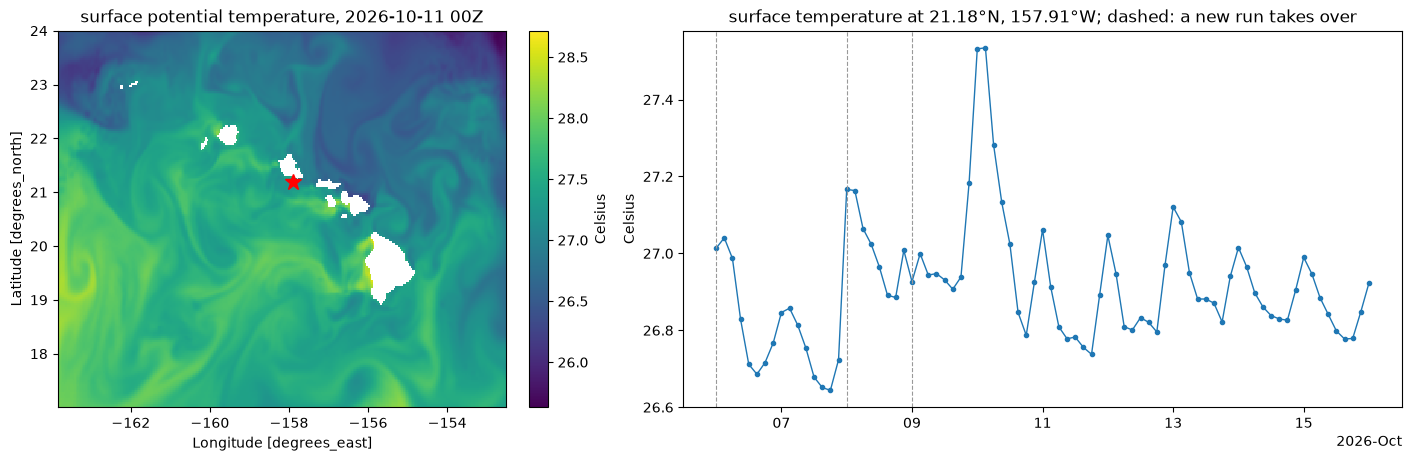

In [15]:
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(14, 4.5), constrained_layout=True,
                               gridspec_kw={'width_ratios': [1, 1.6]})
sst_map.plot(ax=ax0, cmap='viridis', cbar_kwargs={'label': 'Celsius'})
ax0.plot(series.lon, series.lat, 'r*', ms=12)
ax0.set_title(f'surface potential temperature, {pd.Timestamp(sst_map.time.values):%Y-%m-%d %HZ}')
series.plot(ax=ax1, lw=1, marker='.')
for d in SMALL:
    ax1.axvline(d, color='0.6', lw=0.8, ls='--')
ax1.set_title(f'surface temperature at {float(series.lat):.2f}°N, {-float(series.lon):.2f}°W; '
              'dashed: a new run takes over')
ax1.set_ylabel('Celsius')
ax1.set_xlabel('')
plt.show()

## 12. Still unknown before the production build

- **Every file's header.** 15 of 654 files were scanned here. Production scans all of them
  (about 1.5 to 3 s each), and checks the structure of each against the first.
- **Full-length open and read times.** The full best series has 5,497 steps, 2 manifests per
  array and about 0.8 M references. Measure the open and a 23-month point series on the
  scratch build.
- **The time axis against ERDDAP.** ERDDAP `roms_hiig` ends at the last run's end; the
  production validation compares the whole axis with ERDDAP's, and a few point values.
- **The daily update (#4).** The best series changes at its end every day: a new run takes
  over its last 7 days. This build writes the whole series at once; how the daily commit
  re-points those steps is #4's question.
- **Remote destination and browser access.** Nothing here touched Source Cooperative's write
  side or a browser: `build_store.py --dest scratch` and the viewer do.

## 13. Clean up

Deletes the temporary local directory this notebook created, and nothing else.

In [16]:
assert WORK.name.startswith('pacioos-forecast-smoke-') and WORK.parent == Path(tempfile.gettempdir())
shutil.rmtree(WORK)
print('removed', WORK)

removed /tmp/pacioos-forecast-smoke-_li930ri
